# EDA — DONKI SEP and the bridge to OSDR

Exploration of solar energetic particle events and translation of environmental signals into indicators for a crew health app.

> DONKI is an environmental sensor. OSDR is a biological evidence base. The score in this notebook is heuristic and represents neither clinical dose nor diagnosis.

In [9]:
import re
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
BASE_URL = "https://ccmc.gsfc.nasa.gov/DONKI-API/get"
START_DATE, END_DATE = "2026-08-06", "2026-10-04"
assert (pd.Timestamp(END_DATE) - pd.Timestamp(START_DATE)).days <= 60

## 1. DONKI ingestion

In [10]:
def fetch_donki(event_type="SEP", start_date=START_DATE, end_date=END_DATE, timeout=30):
    start, end = pd.Timestamp(start_date), pd.Timestamp(end_date)
    if end < start or (end - start).days > 60: raise ValueError("A janela deve ter no máximo 60 dias.")
    r = requests.get(f"{BASE_URL}/{event_type}", params={"startDate": start.strftime("%Y-%m-%d"), "endDate": end.strftime("%Y-%m-%d")}, timeout=timeout)
    r.raise_for_status(); payload = r.json()
    if not isinstance(payload, list): raise TypeError("Resposta DONKI inesperada")
    return payload

events_raw = fetch_donki()
print(f"Eventos SEP retornados: {len(events_raw)}")
if events_raw: display(pd.json_normalize(events_raw).head(3))

Eventos SEP retornados: 11


,sepID,eventTime,instruments,link,linkedEvents,sentNotifications,submissionTime,versionId
0,2026-08-20T20:23:00-SEP-001,2026-08-20T20:23Z,[{'displayName': 'STEREO A: IMPACT 13-100 MeV'}],https://ccmc.gsfc.nasa.gov/DONKI/view/SEP/4817...,[{'activityID': '2026-08-20T18:48:00-CME-001'}],"[{'messageID': '20260820-AL-004', 'messageIssu...",2026-08-20T20:39Z,1
1,2026-08-21T17:33:00-SEP-001,2026-08-21T17:33Z,[{'displayName': 'STEREO A: IMPACT 13-100 MeV'}],https://ccmc.gsfc.nasa.gov/DONKI/view/SEP/4819...,[{'activityID': '2026-08-21T09:09:00-FLR-001'}...,"[{'messageID': '20260821-AL-005', 'messageIssu...",2026-08-21T21:06Z,2
2,2026-08-22T22:28:00-SEP-001,2026-08-22T22:28Z,[{'displayName': 'STEREO A: IMPACT 13-100 MeV'}],https://ccmc.gsfc.nasa.gov/DONKI/view/SEP/4823...,[{'activityID': '2026-08-21T09:09:00-FLR-001'}...,None,2026-08-24T15:59Z,2


## 2. Normalization and environmental score

In [11]:
def instrument_names(v):
    return "; ".join(x.get("displayName", "") for x in (v or []) if isinstance(x, dict))

def linked_types(v):
    return sorted({m.group(1) for x in (v or []) for m in [re.search(r"-(FLR|CME|IPS)-", x.get("activityID", ""))] if m})

df = pd.DataFrame({"sep_id": [e.get("sepID") for e in events_raw], "event_time": [e.get("eventTime") for e in events_raw], "instruments": [instrument_names(e.get("instruments")) for e in events_raw], "linked_types": [linked_types(e.get("linkedEvents")) for e in events_raw], "notification_count": [len(e.get("sentNotifications") or []) for e in events_raw], "source_link": [e.get("link") for e in events_raw]})
df["event_time"] = pd.to_datetime(df["event_time"], utc=True, errors="coerce")
df["energy_100_mev"] = df["instruments"].str.contains(r"(?:>|≥|>=)\s*100\s*MeV|100\+\s*MeV", case=False, na=False)
df["has_flare"] = df["linked_types"].apply(lambda x: "FLR" in x); df["has_cme"] = df["linked_types"].apply(lambda x: "CME" in x)
daily = df.set_index("event_time").resample("D").agg(events=("sep_id", "count"), high_energy=("energy_100_mev", "sum"), context=("has_flare", "sum"), notifications=("notification_count", lambda x: (x > 0).sum())).fillna(0)
timeline = df.set_index("event_time").sort_index().copy()
timeline["events_24h"] = timeline["sep_id"].rolling("24h").count(); timeline["high_energy_24h"] = timeline["energy_100_mev"].rolling("24h").sum(); timeline["context_24h"] = (timeline["has_flare"] | timeline["has_cme"]).rolling("24h").sum(); timeline["notifications_24h"] = (timeline["notification_count"] > 0).rolling("24h").sum()
timeline["risk_score"] = (100 * (0.35*(timeline["events_24h"]/5).clip(0,1) + 0.30*(timeline["high_energy_24h"]/2).clip(0,1) + 0.20*(timeline["context_24h"]/2).clip(0,1) + 0.15*(timeline["notifications_24h"]/2).clip(0,1))).round(1)
timeline["risk_level"] = pd.cut(timeline["risk_score"], [-1,24,49,74,100], labels=["baixo","moderado","alto","crítico"])
display(df.head())

,sep_id,event_time,instruments,linked_types,notification_count,source_link,energy_100_mev,has_flare,has_cme
0,2026-08-20T20:23:00-SEP-001,2026-08-20 20:23:00+00:00,STEREO A: IMPACT 13-100 MeV,[CME],2,https://ccmc.gsfc.nasa.gov/DONKI/view/SEP/4817...,False,False,True
1,2026-08-21T17:33:00-SEP-001,2026-08-21 17:33:00+00:00,STEREO A: IMPACT 13-100 MeV,"[CME, FLR]",2,https://ccmc.gsfc.nasa.gov/DONKI/view/SEP/4819...,False,True,True
2,2026-08-22T22:28:00-SEP-001,2026-08-22 22:28:00+00:00,STEREO A: IMPACT 13-100 MeV,"[CME, FLR, IPS]",0,https://ccmc.gsfc.nasa.gov/DONKI/view/SEP/4823...,False,True,True
3,2026-09-05T15:45:00-SEP-001,2026-09-05 15:45:00+00:00,GOES-P: SEISS >100 MeV,"[CME, FLR]",2,https://ccmc.gsfc.nasa.gov/DONKI/view/SEP/4855...,True,True,True
4,2026-09-05T16:15:00-SEP-001,2026-09-05 16:15:00+00:00,GOES-P: SEISS >10 MeV,"[CME, FLR]",2,https://ccmc.gsfc.nasa.gov/DONKI/view/SEP/4855...,False,True,True


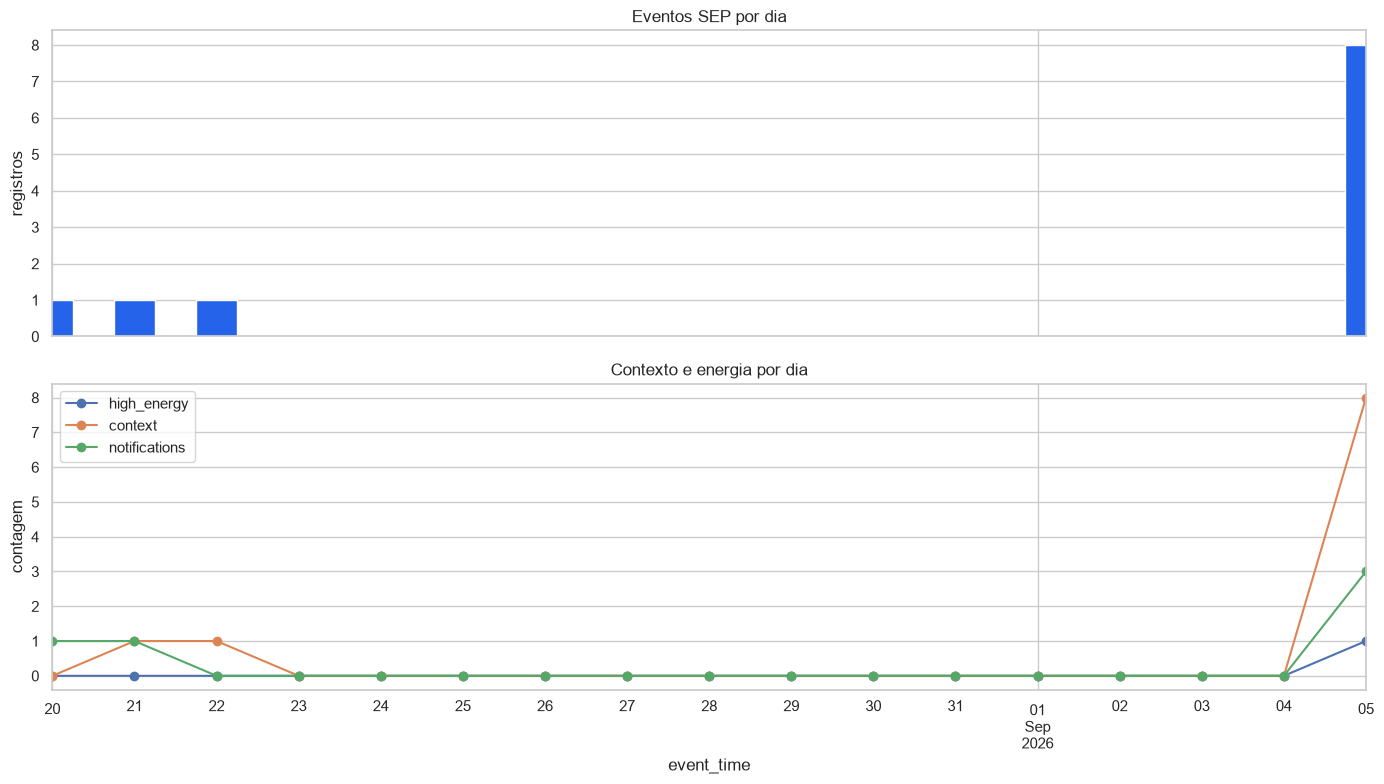

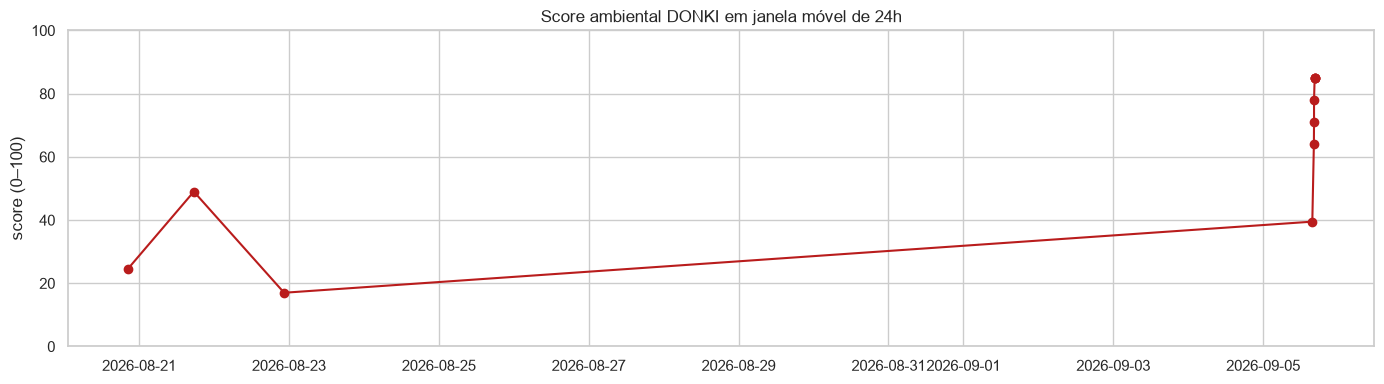

,events_24h,high_energy_24h,context_24h,notifications_24h,risk_score,risk_level
event_time,,,,,,
2026-09-05 16:30:00+00:00,5.0,1.0,5.0,3.0,85.0,crítico
2026-09-05 16:30:00+00:00,6.0,1.0,6.0,3.0,85.0,crítico
2026-09-05 16:30:00+00:00,7.0,1.0,7.0,3.0,85.0,crítico
2026-09-05 16:30:00+00:00,8.0,1.0,8.0,3.0,85.0,crítico
2026-09-05 16:18:00+00:00,4.0,1.0,4.0,3.0,78.0,crítico
2026-09-05 16:18:00+00:00,3.0,1.0,3.0,2.0,71.0,alto
2026-09-05 16:15:00+00:00,2.0,1.0,2.0,2.0,64.0,alto
2026-08-21 17:33:00+00:00,2.0,0.0,2.0,2.0,49.0,moderado
2026-09-05 15:45:00+00:00,1.0,1.0,1.0,1.0,39.5,moderado


In [12]:
fig, ax = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
daily["events"].plot.bar(ax=ax[0], color="#2563eb"); ax[0].set(title="Eventos SEP por dia", ylabel="registros")
daily[["high_energy", "context", "notifications"]].plot(ax=ax[1], marker="o"); ax[1].set(title="Contexto e energia por dia", ylabel="contagem")
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(14,4)); ax.plot(timeline.index, timeline["risk_score"], marker="o", color="#b91c1c"); ax.set(title="Score ambiental DONKI em janela móvel de 24h", ylim=(0,100), ylabel="score (0–100)"); plt.tight_layout(); plt.show()
display(timeline[["events_24h","high_energy_24h","context_24h","notifications_24h","risk_score","risk_level"]].sort_values("risk_score", ascending=False).head(15))

## 3. Integration with Caroline's OSDR EDA

The taxonomy below was extracted from the OSDR notebook: the space radiation hazard, body systems and biomarkers. It does not turn OSDR into a real-time sensor; it helps decide what to monitor after a DONKI environmental alert.

In [13]:
osdr_radiation_reference = pd.DataFrame([
 {"camada":"Hazard", "item":"Radiação espacial", "proxy_osdr":"irradiação, prótons, íons pesados, HZE, gamma, raios X", "indicador_app":"explicação do alerta"},
 {"camada":"Sistema", "item":"Imune / hematológico", "proxy_osdr":"sangue, plasma, PBMC, leucócitos, linfócitos, citocinas", "indicador_app":"hemograma e inflamação"},
 {"camada":"Sistema", "item":"Cardiovascular", "proxy_osdr":"coração, vasos, endotélio, marcadores cardíacos", "indicador_app":"FC/PA e checagem cardiovascular"},
 {"camada":"Sistema", "item":"Neurológico", "proxy_osdr":"cérebro, retina, sistema vestibular, neuroinflamação", "indicador_app":"sintomas e estado funcional"},
 {"camada":"Sistema", "item":"Renal / urinário", "proxy_osdr":"rim, urina, bexiga", "indicador_app":"urina, hidratação e função renal"},
 {"camada":"Sistema", "item":"Musculoesquelético", "proxy_osdr":"osso, músculo, medula e remodelação", "indicador_app":"tendência osso/músculo"},
 {"camada":"Biomarcador", "item":"Dano de DNA / radiação", "proxy_osdr":"DNA damage, telômeros, H2AX, cromossomos, mutações, estresse oxidativo", "indicador_app":"resposta tardia e longitudinal"},
 {"camada":"Biomarcador", "item":"Imunidade / inflamação", "proxy_osdr":"citocinas, IL-6, CRP, leucócitos, linfócitos, NK", "indicador_app":"confirmação biológica pós-evento"},
])
display(osdr_radiation_reference)

,camada,item,proxy_osdr,indicador_app
0,Hazard,Radiação espacial,"irradiação, prótons, íons pesados, HZE, gamma,...",explicação do alerta
1,Sistema,Imune / hematológico,"sangue, plasma, PBMC, leucócitos, linfócitos, ...",hemograma e inflamação
2,Sistema,Cardiovascular,"coração, vasos, endotélio, marcadores cardíacos",FC/PA e checagem cardiovascular
3,Sistema,Neurológico,"cérebro, retina, sistema vestibular, neuroinfl...",sintomas e estado funcional
4,Sistema,Renal / urinário,"rim, urina, bexiga","urina, hidratação e função renal"
5,Sistema,Musculoesquelético,"osso, músculo, medula e remodelação",tendência osso/músculo
6,Biomarcador,Dano de DNA / radiação,"DNA damage, telômeros, H2AX, cromossomos, muta...",resposta tardia e longitudinal
7,Biomarcador,Imunidade / inflamação,"citocinas, IL-6, CRP, leucócitos, linfócitos, NK",confirmação biológica pós-evento


### DONKI × OSDR × app comparison

In [14]:
integration_map = pd.DataFrame([
 {"sinal_donki":"SEP + score alto", "evidencia_osdr":"Dano de DNA / radiação", "indicador":"estresse oxidativo e dano genético", "janela":"imediata + longitudinal", "prioridade":"Alta"},
 {"sinal_donki":"SEP >= 100 MeV", "evidencia_osdr":"Imune / hematológico", "indicador":"hemograma, leucócitos, linfócitos, inflamação", "janela":"alerta + confirmação", "prioridade":"Alta"},
 {"sinal_donki":"Flare/CME associado", "evidencia_osdr":"Cardiovascular e neurológico", "indicador":"FC/PA, sintomas, estado funcional", "janela":"durante e pós-evento", "prioridade":"Média-alta"},
 {"sinal_donki":"Exposição recorrente", "evidencia_osdr":"Renal, musculoesquelético e DNA", "indicador":"urina, função renal, osso/músculo, biomarcadores", "janela":"série longitudinal", "prioridade":"Alta"},
 {"sinal_donki":"Sem SEP detectado", "evidencia_osdr":"baseline e demais hazards", "indicador":"rotina e comparação individual", "janela":"contínua", "prioridade":"Média"},
])
display(integration_map)

,sinal_donki,evidencia_osdr,indicador,janela,prioridade
0,SEP + score alto,Dano de DNA / radiação,estresse oxidativo e dano genético,imediata + longitudinal,Alta
1,SEP >= 100 MeV,Imune / hematológico,"hemograma, leucócitos, linfócitos, inflamação",alerta + confirmação,Alta
2,Flare/CME associado,Cardiovascular e neurológico,"FC/PA, sintomas, estado funcional",durante e pós-evento,Média-alta
3,Exposição recorrente,"Renal, musculoesquelético e DNA","urina, função renal, osso/músculo, biomarcadores",série longitudinal,Alta
4,Sem SEP detectado,baseline e demais hazards,rotina e comparação individual,contínua,Média


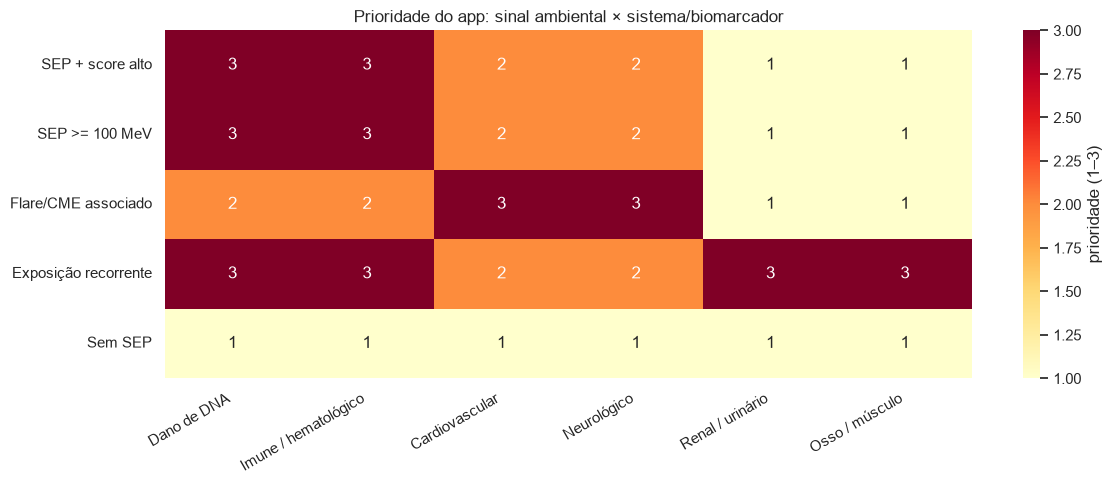

In [15]:
priority_matrix = pd.DataFrame({"Dano de DNA":[3,3,2,3,1], "Imune / hematológico":[3,3,2,3,1], "Cardiovascular":[2,2,3,2,1], "Neurológico":[2,2,3,2,1], "Renal / urinário":[1,1,1,3,1], "Osso / músculo":[1,1,1,3,1]}, index=["SEP + score alto", "SEP >= 100 MeV", "Flare/CME associado", "Exposição recorrente", "Sem SEP"])
plt.figure(figsize=(12,5)); sns.heatmap(priority_matrix, annot=True, fmt="d", cmap="YlOrRd", vmin=1, vmax=3, cbar_kws={"label":"prioridade (1–3)"}); plt.title("Prioridade do app: sinal ambiental × sistema/biomarcador"); plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

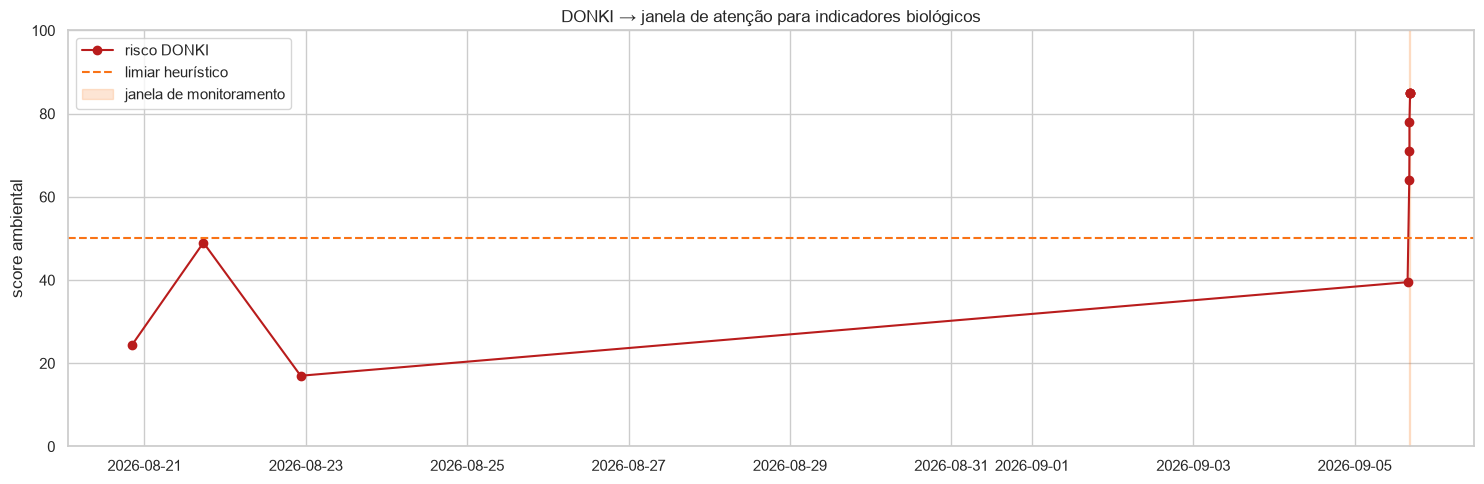

,risk_score,risk_level,events_24h,high_energy_24h,context_24h,notifications_24h,monitoring_window,acao_app
event_time,,,,,,,,
2026-09-05 16:30:00+00:00,85.0,crítico,5.0,1.0,5.0,3.0,True,priorizar protocolo e avaliação
2026-09-05 16:30:00+00:00,85.0,crítico,6.0,1.0,6.0,3.0,True,priorizar protocolo e avaliação
2026-09-05 16:30:00+00:00,85.0,crítico,7.0,1.0,7.0,3.0,True,priorizar protocolo e avaliação
2026-09-05 16:30:00+00:00,85.0,crítico,8.0,1.0,8.0,3.0,True,priorizar protocolo e avaliação
2026-09-05 16:18:00+00:00,78.0,crítico,4.0,1.0,4.0,3.0,True,priorizar protocolo e avaliação
2026-09-05 16:18:00+00:00,71.0,alto,3.0,1.0,3.0,2.0,True,confirmar sensores e intensificar observação
2026-09-05 16:15:00+00:00,64.0,alto,2.0,1.0,2.0,2.0,True,confirmar sensores e intensificar observação
2026-08-21 17:33:00+00:00,49.0,moderado,2.0,0.0,2.0,2.0,False,manter baseline e observar tendência
2026-09-05 15:45:00+00:00,39.5,moderado,1.0,1.0,1.0,1.0,False,manter baseline e observar tendência


In [16]:
integrated = timeline.copy(); integrated["monitoring_window"] = integrated["risk_score"] >= 50
fig, ax = plt.subplots(figsize=(15,5)); ax.plot(integrated.index, integrated["risk_score"], marker="o", color="#b91c1c", label="risco DONKI"); ax.axhline(50, color="#f97316", linestyle="--", label="limiar heurístico"); ax.fill_between(integrated.index, 0, 100, where=integrated["monitoring_window"].fillna(False), color="#f97316", alpha=.18, step="mid", label="janela de monitoramento"); ax.set(title="DONKI → janela de atenção para indicadores biológicos", ylim=(0,100), ylabel="score ambiental"); ax.legend(); plt.tight_layout(); plt.show()
monitoring_plan = integrated[["risk_score","risk_level","events_24h","high_energy_24h","context_24h","notifications_24h","monitoring_window"]].copy()
monitoring_plan["acao_app"] = np.select([monitoring_plan["risk_score"] >= 75, monitoring_plan["risk_score"] >= 50, monitoring_plan["risk_score"] >= 25], ["priorizar protocolo e avaliação", "confirmar sensores e intensificar observação", "manter baseline e observar tendência"], default="rotina")
display(monitoring_plan.sort_values("risk_score", ascending=False).head(20))

## 4. Recommended indicators for the first version

**DONKI:** SEP score 0–100, events in 24 h, maximum available energy, flare/CME, notifications, episode duration and accumulated exposure.

**OSDR + crew data:** blood count/leukocytes, inflammatory markers, DNA damage/oxidative stress, HR/BP, neurological symptoms, urine/renal function and bone/muscle trend.

**Product rule:** DONKI triggers context and priority; it does not produce a diagnosis on its own. The app must show the signal that triggered the alert, the time window and the biological indicator to confirm.

## 5. DONKI × Mars RAD bridge — physical exposure

Giovanni's notebook uses data from the RAD instrument on the Curiosity rover, on the surface of Mars. The main difference is:

- **DONKI:** remote/environmental signal of solar activity and energetic particles; it indicates when risk may rise.
- **RAD:** local measurement of dose and LET distribution; it indicates how much radiation the detector received in that environment.

The combination is useful for the app, but it must not be read as a direct time correlation: RAD data come from the Martian surface and DONKI events are heliospheric/space observations.

In [17]:
mars_rad_catalog = pd.DataFrame([
 {"indicador":"Dose_B_uGy_h", "unidade":"µGy/h", "o_que_mede":"componente de dose registrada pelo detector B", "especificidade_marte":"alta", "valor_para_app":"baseline e tendência de exposição local", "camada":"exposição física"},
 {"indicador":"Dose_E_uGy_h", "unidade":"µGy/h", "o_que_mede":"componente de dose registrada pelo detector E", "especificidade_marte":"alta", "valor_para_app":"separar contribuições de dose", "camada":"exposição física"},
 {"indicador":"LET_Energy_Centers", "unidade":"keV/µm", "o_que_mede":"centro de cada faixa de transferência linear de energia", "especificidade_marte":"média", "valor_para_app":"caracterizar poder de deposição de energia", "camada":"qualidade da radiação"},
 {"indicador":"LET_Counts", "unidade":"contagem", "o_que_mede":"número de partículas em cada faixa de LET", "especificidade_marte":"média", "valor_para_app":"identificar cauda de partículas de alto LET", "camada":"espectro"},
 {"indicador":"Q(LET)", "unidade":"adimensional", "o_que_mede":"fator de qualidade radiobiológico aproximado", "especificidade_marte":"não — conceito geral", "valor_para_app":"converter dose física em proxy de dose equivalente", "camada":"risco radiobiológico"},
 {"indicador":"Dose × Q(LET)", "unidade":"proxy µSv/h", "o_que_mede":"dose ponderada pela qualidade da radiação", "especificidade_marte":"não — exige calibração", "valor_para_app":"indicador de impacto comparável entre episódios", "camada":"risco radiobiológico"},
])
display(mars_rad_catalog)

,indicador,unidade,o_que_mede,especificidade_marte,valor_para_app,camada
0,Dose_B_uGy_h,µGy/h,componente de dose registrada pelo detector B,alta,baseline e tendência de exposição local,exposição física
1,Dose_E_uGy_h,µGy/h,componente de dose registrada pelo detector E,alta,separar contribuições de dose,exposição física
2,LET_Energy_Centers,keV/µm,centro de cada faixa de transferência linear d...,média,caracterizar poder de deposição de energia,qualidade da radiação
3,LET_Counts,contagem,número de partículas em cada faixa de LET,média,identificar cauda de partículas de alto LET,espectro
4,Q(LET),adimensional,fator de qualidade radiobiológico aproximado,não — conceito geral,converter dose física em proxy de dose equival...,risco radiobiológico
5,Dose × Q(LET),proxy µSv/h,dose ponderada pela qualidade da radiação,não — exige calibração,indicador de impacto comparável entre episódios,risco radiobiológico


### What is specific to Mars?

Specific to the Mars RAD context: the surface environment, the onboard detector, the local radiation field, the rover geometry, the Martian atmosphere and the dose rates measured on the ground. Reusable in the app: physical dose, LET, counts per bin, quality factor, equivalent dose and accumulation over time.

An astronaut's exposure in transit or on the surface may differ because of shielding, suit, habitat, altitude, atmosphere, extravehicular activity and position. RAD should therefore serve as a reference/calibration, not as a substitute for a crew dosimeter.

In [18]:
def provisional_quality_factor(let_array):
    """Q(L) provisório usado no notebook RAD; validar com protocolo radiobiológico."""
    L = np.asarray(let_array, dtype=float)
    Q = np.ones_like(L)
    mid = (L >= 10) & (L <= 100); high = L > 100
    Q[mid] = 0.32 * L[mid] - 2.2
    Q[high] = 300 / np.sqrt(L[high])
    return Q

def summarize_rad_dataframe(rad_df):
    """Extrai indicadores do df_dose produzido pelo notebook RAD, quando disponível."""
    out = rad_df.copy()
    for c in ["Dose_B_uGy_h", "Dose_E_uGy_h"]:
        if c not in out: out[c] = np.nan
    out["Dose_total_uGy_h"] = out[["Dose_B_uGy_h", "Dose_E_uGy_h"]].sum(axis=1, min_count=1)
    if {"LET_Energy_Centers", "LET_Counts"}.issubset(out.columns):
        out["LET_weighted_mean_keV_um"] = out.apply(lambda r: np.average(r["LET_Energy_Centers"], weights=r["LET_Counts"]) if isinstance(r["LET_Energy_Centers"], np.ndarray) and isinstance(r["LET_Counts"], np.ndarray) and r["LET_Counts"].sum() > 0 else np.nan, axis=1)
        out["LET_high_fraction"] = out.apply(lambda r: r["LET_Counts"][r["LET_Energy_Centers"] > 100].sum() / r["LET_Counts"].sum() if isinstance(r["LET_Energy_Centers"], np.ndarray) and isinstance(r["LET_Counts"], np.ndarray) and r["LET_Counts"].sum() > 0 else np.nan, axis=1)
        out["Q_weighted"] = out["LET_weighted_mean_keV_um"].map(lambda x: provisional_quality_factor([x])[0] if pd.notna(x) else np.nan)
        out["Dose_equiv_proxy_uSv_h"] = out["Dose_total_uGy_h"] * out["Q_weighted"]
    return out

if "df_dose" in globals():
    rad_features = summarize_rad_dataframe(df_dose)
    display(rad_features.head())
else:
    rad_features = pd.DataFrame()
    print("df_dose ainda não existe. Execute a extração do notebook RAD para ativar os indicadores locais de dose e LET.")

df_dose ainda não existe. Execute a extração do notebook RAD para ativar os indicadores locais de dose e LET.


### Scope and indicator comparison

In [19]:
scope_comparison = pd.DataFrame([
 {"fonte":"DONKI SEP", "localização":"observação espacial/heliosférica", "mede_dose_local":"Não", "indicadores_principais":"eventos SEP, energia disponível, flare/CME, notificações", "papel_no_app":"alerta antecipado e contexto"},
 {"fonte":"RAD Curiosity", "localização":"superfície de Marte", "mede_dose_local":"Sim, no detector", "indicadores_principais":"Dose_B, Dose_E, LET, contagens, Q(LET)", "papel_no_app":"referência de exposição física e calibração"},
 {"fonte":"Dosímetro da tripulação", "localização":"corpo/traje/habitat", "mede_dose_local":"Sim, no ponto de uso", "indicadores_principais":"dose acumulada, taxa de dose, espectro se disponível", "papel_no_app":"fonte operacional primária"},
 {"fonte":"OSDR", "localização":"experimentos biológicos", "mede_dose_local":"Não necessariamente", "indicadores_principais":"DNA, inflamação, hematologia, sistemas fisiológicos", "papel_no_app":"evidência para selecionar biomarcadores"},
])
display(scope_comparison)

,fonte,localização,mede_dose_local,indicadores_principais,papel_no_app
0,DONKI SEP,observação espacial/heliosférica,Não,"eventos SEP, energia disponível, flare/CME, no...",alerta antecipado e contexto
1,RAD Curiosity,superfície de Marte,"Sim, no detector","Dose_B, Dose_E, LET, contagens, Q(LET)",referência de exposição física e calibração
2,Dosímetro da tripulação,corpo/traje/habitat,"Sim, no ponto de uso","dose acumulada, taxa de dose, espectro se disp...",fonte operacional primária
3,OSDR,experimentos biológicos,Não necessariamente,"DNA, inflamação, hematologia, sistemas fisioló...",evidência para selecionar biomarcadores


,indicador,fonte,disponibilidade,prioridade,tipo
0,Score SEP DONKI,DONKI,já calculado,5,alerta ambiental
1,Dose física local,RAD/dosímetro,RAD tem referência; tripulação ainda não,5,exposição
4,Dose equivalente proxy,RAD + Q(LET),requer validação/calibração,5,risco radiobiológico
2,LET médio ponderado,RAD/dosímetro espectral,extraível quando arrays existirem,4,qualidade da radiação
3,Fração LET > 100 keV/µm,RAD/dosímetro espectral,extraível quando arrays existirem,4,partículas de alto LET
5,Dano de DNA / inflamação,OSDR + biometria,proxy; não em tempo real,4,resposta biológica


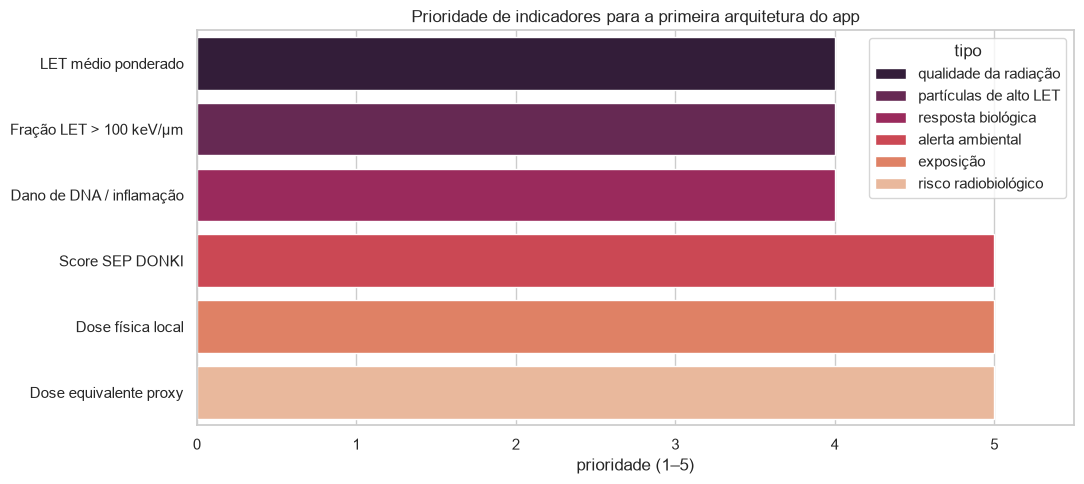

In [20]:
# Indicator map: current availability and product priority.
indicator_priority = pd.DataFrame([
 {"indicador":"Score SEP DONKI", "fonte":"DONKI", "disponibilidade":"já calculado", "prioridade":5, "tipo":"alerta ambiental"},
 {"indicador":"Dose física local", "fonte":"RAD/dosímetro", "disponibilidade":"RAD tem referência; tripulação ainda não", "prioridade":5, "tipo":"exposição"},
 {"indicador":"LET médio ponderado", "fonte":"RAD/dosímetro espectral", "disponibilidade":"extraível quando arrays existirem", "prioridade":4, "tipo":"qualidade da radiação"},
 {"indicador":"Fração LET > 100 keV/µm", "fonte":"RAD/dosímetro espectral", "disponibilidade":"extraível quando arrays existirem", "prioridade":4, "tipo":"partículas de alto LET"},
 {"indicador":"Dose equivalente proxy", "fonte":"RAD + Q(LET)", "disponibilidade":"requer validação/calibração", "prioridade":5, "tipo":"risco radiobiológico"},
 {"indicador":"Dano de DNA / inflamação", "fonte":"OSDR + biometria", "disponibilidade":"proxy; não em tempo real", "prioridade":4, "tipo":"resposta biológica"},
])
display(indicator_priority.sort_values("prioridade", ascending=False))
plt.figure(figsize=(11,5)); sns.barplot(data=indicator_priority.sort_values("prioridade"), x="prioridade", y="indicador", hue="tipo", dodge=False, palette="rocket"); plt.xlim(0,5.5); plt.title("Prioridade de indicadores para a primeira arquitetura do app"); plt.xlabel("prioridade (1–5)"); plt.ylabel(""); plt.tight_layout(); plt.show()

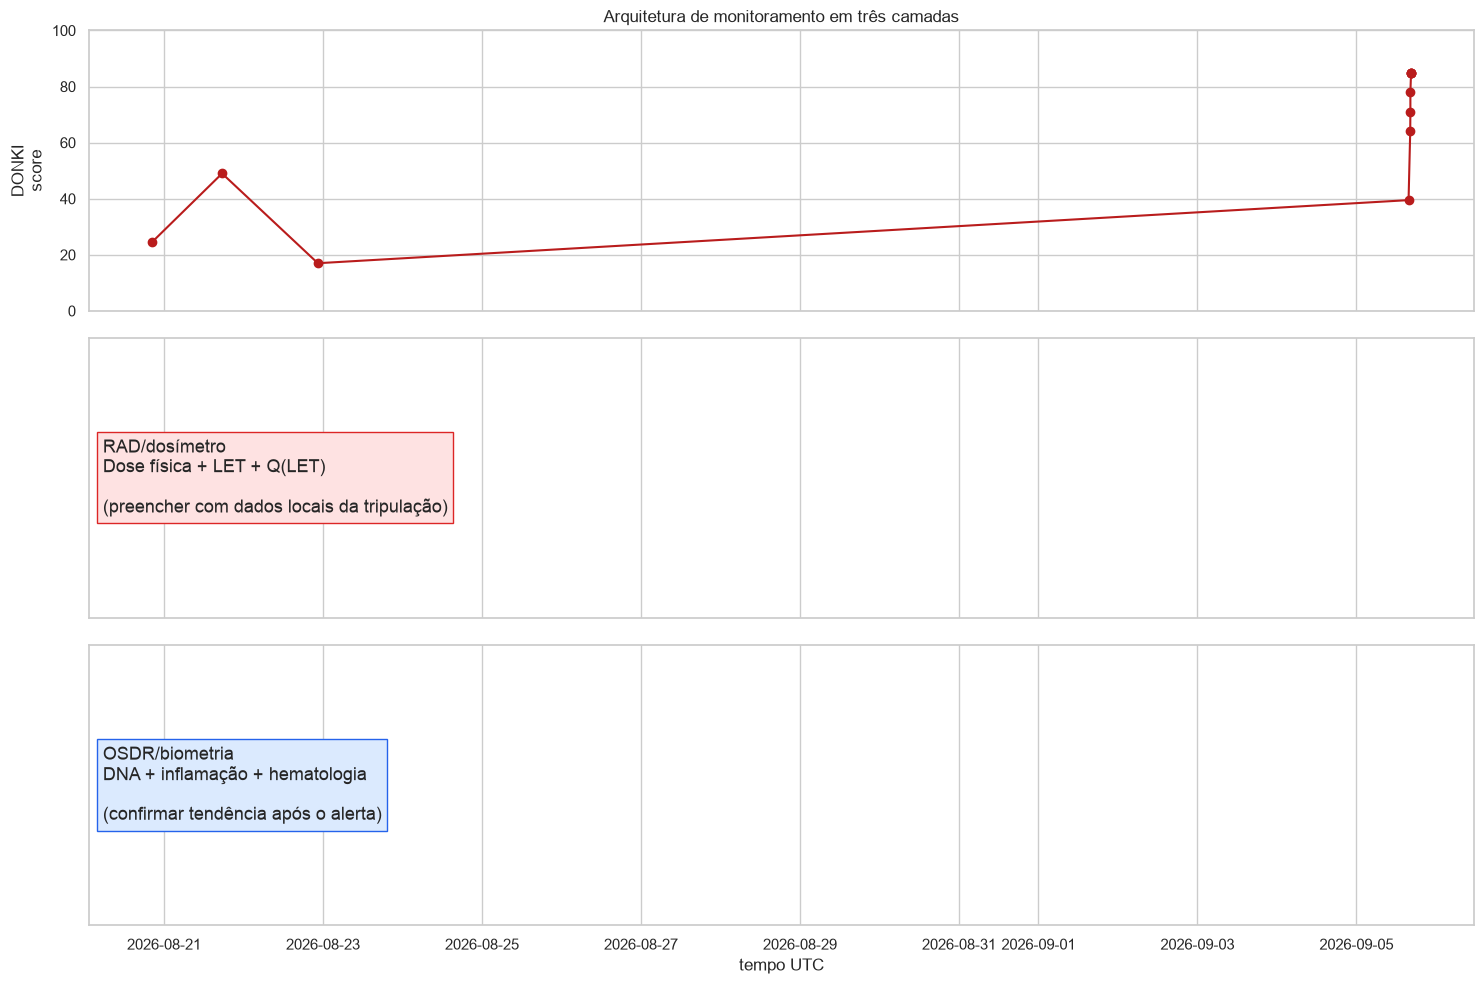

In [21]:
# Comparison chart: the same episode can have a DONKI signal, physical dose and a biological response.
fig, axes = plt.subplots(3, 1, figsize=(15, 10), sharex=True)
axes[0].plot(timeline.index, timeline["risk_score"], color="#b91c1c", marker="o"); axes[0].set_ylabel("DONKI\nscore"); axes[0].set_ylim(0,100); axes[0].set_title("Arquitetura de monitoramento em três camadas")
axes[1].text(0.01, 0.5, "RAD/dosímetro\nDose física + LET + Q(LET)\n\n(preencher com dados locais da tripulação)", transform=axes[1].transAxes, va="center", fontsize=13, bbox={"facecolor":"#fee2e2", "edgecolor":"#dc2626"}); axes[1].set_yticks([])
axes[2].text(0.01, 0.5, "OSDR/biometria\nDNA + inflamação + hematologia\n\n(confirmar tendência após o alerta)", transform=axes[2].transAxes, va="center", fontsize=13, bbox={"facecolor":"#dbeafe", "edgecolor":"#2563eb"}); axes[2].set_yticks([])
plt.xlabel("tempo UTC"); plt.tight_layout(); plt.show()

## 6. Mars-specific conclusion

Mars radiation offers three new, strong indicators for the app: **physical dose rate**, **mean LET/high-LET tail** and **quality-weighted equivalent dose**. They are closer to radiobiological risk than counting SEP events alone.

The recommended architecture is: **DONKI anticipates/contextualizes → RAD/dosimeter measures the actual exposure → OSDR guides which biological responses to follow**. For the mission, the crew dosimeter must be the operational source; RAD is a reference for the Martian environment and OSDR is a reference for biomarkers.

Before using the Dose × Q(LET) indicator, validate units, the definition of channels B/E, the Q(L) formula, detector calibration, shielding and the conversion to dose equivalent in sieverts.

## 7. Possible correlations between RAD and OSDR

RAD provides physical exposure variables; OSDR provides evidence of biological responses. The following table records hypotheses that can be tested once we have paired data from a mission or experiment.

In [22]:
correlation_hypotheses = pd.DataFrame([
    {"exposicao_rad": "Dose_total_uGy_h", "resposta_osdr": "Dano de DNA / radiação", "direcao_esperada": "+", "hipotese": "Maior dose física acompanha maior sinal de dano de DNA/estresse oxidativo", "prioridade": "Alta"},
    {"exposicao_rad": "Dose_equiv_proxy_uSv_h", "resposta_osdr": "Imunidade / inflamação", "direcao_esperada": "+", "hipotese": "Dose equivalente maior pode acompanhar citocinas, CRP ou alterações leucocitárias", "prioridade": "Alta"},
    {"exposicao_rad": "LET_weighted_mean_keV_um", "resposta_osdr": "Dano de DNA / radiação", "direcao_esperada": "+", "hipotese": "Maior LET pode representar maior impacto biológico por unidade de dose", "prioridade": "Alta"},
    {"exposicao_rad": "LET_high_fraction", "resposta_osdr": "Imune / hematológico", "direcao_esperada": "+", "hipotese": "Maior fração de alto LET pode justificar vigilância hematológica reforçada", "prioridade": "Média-alta"},
    {"exposicao_rad": "Dose acumulada", "resposta_osdr": "Renal / urinário", "direcao_esperada": "?", "hipotese": "Investigar associação longitudinal; não é esperado efeito agudo simples", "prioridade": "Média"},
    {"exposicao_rad": "Dose acumulada", "resposta_osdr": "Musculoesquelético", "direcao_esperada": "?", "hipotese": "Separar efeito de radiação do efeito de microgravidade e duração da missão", "prioridade": "Média"},
])
display(correlation_hypotheses)

,exposicao_rad,resposta_osdr,direcao_esperada,hipotese,prioridade
0,Dose_total_uGy_h,Dano de DNA / radiação,+,Maior dose física acompanha maior sinal de dan...,Alta
1,Dose_equiv_proxy_uSv_h,Imunidade / inflamação,+,Dose equivalente maior pode acompanhar citocin...,Alta
2,LET_weighted_mean_keV_um,Dano de DNA / radiação,+,Maior LET pode representar maior impacto bioló...,Alta
3,LET_high_fraction,Imune / hematológico,+,Maior fração de alto LET pode justificar vigil...,Média-alta
4,Dose acumulada,Renal / urinário,?,Investigar associação longitudinal; não é espe...,Média
5,Dose acumulada,Musculoesquelético,?,Separar efeito de radiação do efeito de microg...,Média


TypeError: Image data of dtype object cannot be converted to float

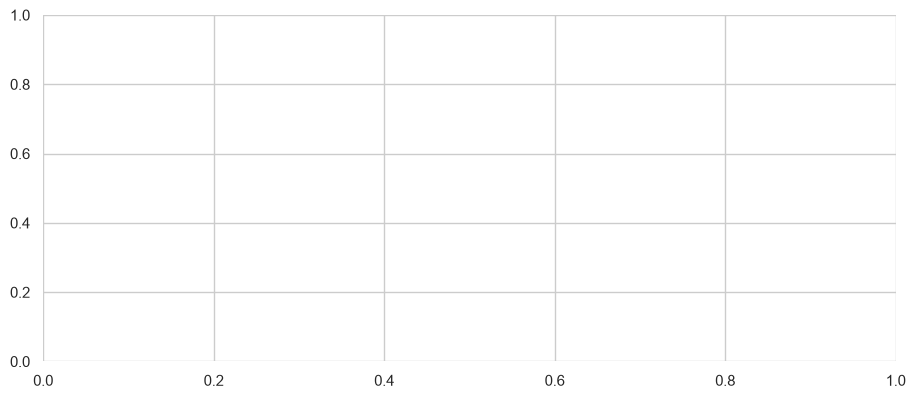

In [23]:
direction_matrix = correlation_hypotheses.pivot(index="exposicao_rad", columns="resposta_osdr", values="direcao_esperada").replace({"+": 1, "-": -1, "?": 0}).fillna(0).astype(float)
plt.figure(figsize=(11, 4.5))
sns.heatmap(direction_matrix, annot=True, fmt="g", cmap="vlag", center=0, linewidths=.5, cbar_kws={"label": "+ esperado | 0 incerto | - inverso"})
plt.title("Hipóteses de correlação RAD × OSDR — não são coeficientes observados")
plt.xlabel("resposta biológica baseada no OSDR"); plt.ylabel("exposição física baseada no RAD"); plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.show()

### Statistical correlation: prepared, but dependent on paired data

We do not compute Pearson/Spearman with the current tables because Giovanni's RAD data and OSDR do not represent the same crew, mission, time window or experimental unit. The function below is ready to receive an RAD exposure table and an OSDR biomarker table aligned by time/observation.

In [ ]:
def correlate_rad_osdr(rad_ts, osdr_ts, time_col="timestamp", tolerance="3D"):
    """Calcula correlações apenas quando RAD e biomarcadores estão pareados no tempo."""
    left, right = rad_ts.copy(), osdr_ts.copy()
    left[time_col] = pd.to_datetime(left[time_col], utc=True); right[time_col] = pd.to_datetime(right[time_col], utc=True)
    left = left.sort_values(time_col); right = right.sort_values(time_col)
    merged = pd.merge_asof(left, right, on=time_col, direction="nearest", tolerance=pd.Timedelta(tolerance), suffixes=("_rad", "_osdr"))
    rad_cols = [c for c in ["Dose_total_uGy_h", "Dose_equiv_proxy_uSv_h", "LET_weighted_mean_keV_um", "LET_high_fraction"] if c in merged]
    bio_cols = [c for c in merged.columns if c not in rad_cols + [time_col] and pd.api.types.is_numeric_dtype(merged[c])]
    rows = []
    for x in rad_cols:
        for y in bio_cols:
            pair = merged[[x, y]].dropna()
            if len(pair) >= 3:
                rows.append({"exposicao": x, "biomarcador": y, "n_pares": len(pair), "pearson": pair[x].corr(pair[y], method="pearson"), "spearman": pair[x].corr(pair[y], method="spearman")})
    return merged, pd.DataFrame(rows)

if "rad_timeseries" in globals() and "osdr_health_timeseries" in globals():
    rad_osdr_joined, rad_osdr_correlations = correlate_rad_osdr(rad_timeseries, osdr_health_timeseries)
    display(rad_osdr_correlations.sort_values("spearman", ascending=False))
else:
    print("Correlação estatística não executada: forneça rad_timeseries e osdr_health_timeseries pareadas.")
    print("Colunas RAD esperadas:", ["timestamp", "Dose_total_uGy_h", "Dose_equiv_proxy_uSv_h", "LET_weighted_mean_keV_um", "LET_high_fraction"])
    print("Colunas OSDR sugeridas:", ["timestamp", "dna_damage", "oxidative_stress", "inflammation", "leukocytes", "lymphocytes"])

### Reading for the app

The first correlation to validate should be **equivalent dose/LET × DNA damage**, followed by **equivalent dose × inflammation/hematology**. Correlations with kidney, bone and muscle must be treated as longitudinal and adjusted for mission duration, microgravity, physical activity, hydration and other hazards.